# gpOptimizer: Single-Task

In [1]:
## First, install the right version of gpCAM, and matplotlib
#!pip install gpcam~=8.7.0
#!pip install matplotlib

## Setup

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from gpcam import GPOptimizer
import time
from distributed import Client
client = Client()

%load_ext autoreload
%autoreload 2

In [3]:
from itertools import product
x_pred1D = np.linspace(0,1,1000).reshape(-1,1)

## Data

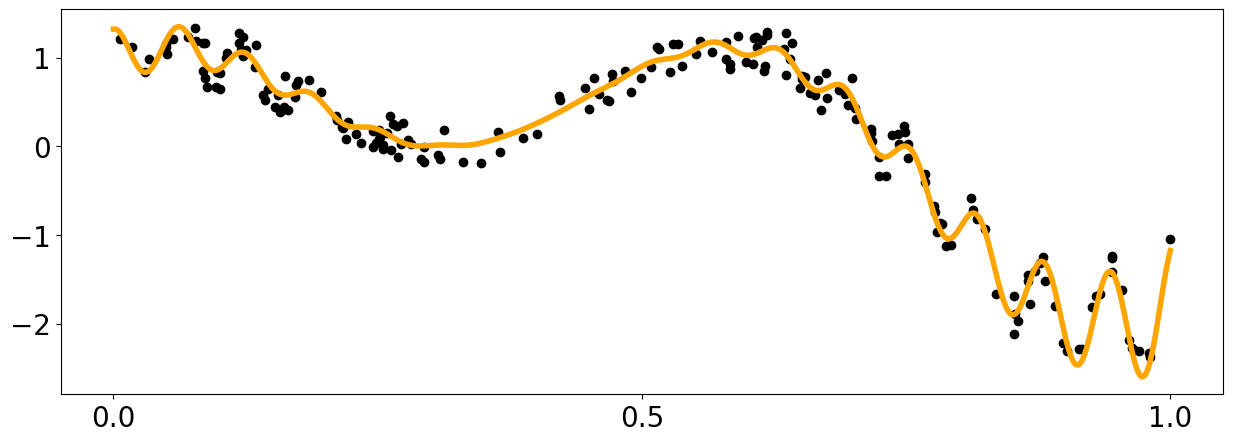

In [4]:
x = np.linspace(0,600,1000)
def f1(x):
    return np.sin(5. * x) + np.cos(10. * x) + (2.* (x-0.4)**2) * np.cos(100. * x)

x_data = np.random.rand(200).reshape(-1,1) 
y_data = f1(x_data[:,0]) + (np.random.rand(len(x_data))-0.5) * 0.5

plt.figure(figsize = (15,5))
plt.xticks([0.,0.5,1.0])
plt.yticks([-2,-1,0.,1])
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.plot(x_pred1D,f1(x_pred1D), color = 'orange', linewidth = 4)
plt.scatter(x_data[:,0],y_data, color = 'black')

## Customizing a Gaussian Process

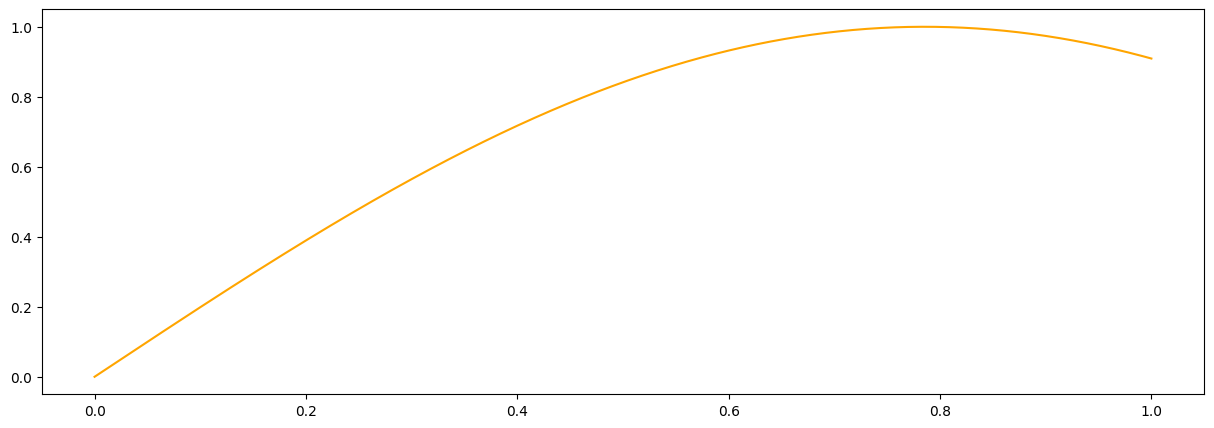

In [5]:
from gpcam.kernels import *
from scipy import sparse
def my_noise(x,hps):
    #This is a simple noise function, but can be arbitrarily complex using many hyperparameters.
    #The noise can be a vector, a matrix, or a sparse matrix in case gp2Scale is used.  
    return np.zeros(len(x)) + hps[2]

#stationary
def skernel(x1,x2,hps):
    #The kernel follows the mathematical definition of a kernel. This
    #means there is no limit to the variety of kernels you can define.
    d = get_distance_matrix(x1,x2)
    return hps[0] * matern_kernel_diff1(d,hps[1])


def meanf(x, hps):
    #This ios a simple mean function but it can be arbitrarily complex using many hyperparameters.
    return np.sin(hps[3] * x[:,0])

#it is a good idea to plot the prior mean function to make sure we did not mess up
plt.figure(figsize = (15,5))
plt.plot(x_pred1D,meanf(x_pred1D, np.array([1.,1.,5.0,2.])), color = 'orange', label = 'task1')

## Initialization and different training options

In [6]:
st = time.time()
my_gpo = GPOptimizer(x_data,y_data,
            init_hyperparameters = np.ones((2))/10.,  # we need enough of those for kernel, noise, and prior mean functions
            noise_variances=np.ones(y_data.shape) * 0.01, # providing noise variances and a noise function will raise a warning 
            compute_device='cpu', 
            kernel_function=skernel, 
            #kernel_function_grad=None, 
            #prior_mean_function=meanf, 
            #prior_mean_function_grad=None,
            #noise_function=my_noise,
            gp2Scale = False, 
            #linalg_mode='Inv',
            gradient_per_direction=True,
            )

print("Initial likelihood: ", my_gpo.log_likelihood())
hps_bounds = np.array([[0.01,10.], #signal variance for the kernel
                       [0.01,10.], #length scale for the kernel
                       #[0.001,0.1],  #noise
                       #[0.01,1.]  #mean
                      ])

#the following is not needed, this is just to show how data is replaced or appended via tell()
x_update = np.array([0.1,0.2,0.5]).reshape(3,1)
y_update = f1(x_update[:,0]) + (np.random.rand(len(x_update))-0.5) * 0.5
my_gpo.tell(x_update, 
            y_update, 
            noise_variances=np.ones(y_update.shape) * 0.05,
            append=True, rank_n_update=True)


print("Standard Training (local)")
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, info = True, n_restarts=4)
print("Result=", hps, "after ", time.time() - st, " seconds")
print("ML: ",my_gpo.log_likelihood())
print("")

print("Bayesian optimization Training")
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, method='bo', max_iter=20)
print("Result=", hps, "after ", time.time() - st, " seconds")
print("ML: ",my_gpo.log_likelihood())
print("")

print("ADAM")
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, info = True, max_iter = 100, method="adam")
print("Result=", hps, "after ", time.time() - st, " seconds")
print("ML: ",my_gpo.log_likelihood())
print("")

print("Global Training")
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, method='global', max_iter = 20)
print("Result=", hps, "after ", time.time() - st, " seconds")
print("ML: ",my_gpo.log_likelihood())
print("")

print("MCMC Training")
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, method='mcmc')
print("Result=", hps, "after ", time.time() - st, " seconds")
print("ML: ",my_gpo.log_likelihood())
print("")

print("HGDL Training")
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, method='hgdl', max_iter=2, dask_client=client)
print("Result=", hps, "after ", time.time() - st, " seconds")
print("ML: ",my_gpo.log_likelihood())
print("")

Initial likelihood:  -209.25868920346332
Standard Training (local)
fvGP local optimization, start 1 of 4
fvGP local iteration 1: f(x)= -6.445104549445915
fvGP local iteration 2: f(x)= -12.29761387322128
fvGP local iteration 3: f(x)= -12.54458809601664
fvGP local iteration 4: f(x)= -12.555753807516027
fvGP local iteration 5: f(x)= -12.561662236570157
fvGP local iteration 6: f(x)= -12.615300716197936
fvGP local iteration 7: f(x)= -12.724502053071404
fvGP local iteration 8: f(x)= -13.156910342238035
fvGP local iteration 9: f(x)= -16.321326094565592
fvGP local iteration 10: f(x)= -16.33135004626027
fvGP local iteration 11: f(x)= -16.715065889506178
fvGP local iteration 12: f(x)= -16.717015775426916
fvGP local iteration 13: f(x)= -16.71711022918919
fvGP local optimization, start 2 of 4
fvGP local iteration 1: f(x)= 2235.214129708474
fvGP local iteration 2: f(x)= 505.0679856617893
fvGP local iteration 3: f(x)= 316.85727172020745
fvGP local iteration 4: f(x)= -1.1397410003188782
fvGP local it

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp_bo.py:812: UserWarning: method='bo' returned the hyperparameters it started from: none of the 16 evaluated points improved on them (stopping reason: 'converged'). A marginal likelihood typically has a narrow ridge along which the signal variance and the length scales trade off together; a space-filling design cannot land on such a ridge and an axis-aligned surrogate cannot follow it, and both get rapidly worse as the number of hyperparameters grows (here 2). Consider method='local' or method='mcmc', which follow a ridge directly and are the better choice whenever the likelihood is cheap enough to evaluate many times, or reduce the number of hyperparameters. If the stopping reason above is 'converged', the run also ended before the budget was spent -- raise bo_args['patience'] to let it continue.
  warnings.warn(


Result= [0.861995   0.05479066] after  10.979154348373413  seconds
ML:  16.717111798345883

ADAM
fvGP adam iteration 1 out of 100: f(x)= -16.717111798345883, |grad|= 0.09701346180785743
fvGP adam iteration 10 out of 100: f(x)= -16.130137090432896, |grad|= 240.99186039520194
fvGP adam iteration 20 out of 100: f(x)= -16.715500700298833, |grad|= 9.30268574910927
fvGP adam iteration 30 out of 100: f(x)= -16.637096539169335, |grad|= 85.11853682721353
fvGP adam iteration 40 out of 100: f(x)= -16.6804265361707, |grad|= 57.54532055739899
fvGP adam iteration 50 out of 100: f(x)= -16.708444485466572, |grad|= 27.537992840174297
fvGP adam iteration 60 out of 100: f(x)= -16.714678105043163, |grad|= 14.233042026960712
fvGP adam iteration 70 out of 100: f(x)= -16.71599275081178, |grad|= 9.749593234995857
fvGP adam iteration 80 out of 100: f(x)= -16.71648759382836, |grad|= 7.472762456476293
fvGP adam iteration 90 out of 100: f(x)= -16.71687234761322, |grad|= 4.697557425302921
fvGP adam iteration 100 o

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1505: UserWarning: Training with method=`adam` returned hyperparameters with a lower log marginal likelihood (16.71710840832762 vs. 16.717111798345883); they were rejected and the previous hyperparameters kept. Pass `accept_only_if_improved=False` to accept them anyway.
  warnings.warn(


Result= [0.861995   0.05479066] after  40.589590072631836  seconds
ML:  16.717111798344547

MCMC Training
Result= [1.23278263 0.06284597] after  57.54641008377075  seconds
ML:  16.288175679729306

HGDL Training
Result= [0.86223956 0.05479424] after  79.04183983802795  seconds
ML:  16.71711222203524



In [7]:
#You can always test your gradient like this before running local optimizers
my_gpo.test_log_likelihood_gradient(np.array([1.,1.]), epsilon=1e-6)

(array([  89.49878509, -254.07904161]), array([  89.49911542, -254.07849992]))

In [8]:
#everything the optimizer holds about the data
my_gpo.get_data().keys()

dict_keys(['input dim', 'multi-task mode', 'x data', 'y data', 'original y data', 'measurement variances', 'hyperparameters', 'cost function'])

### More advanced: Asynchronous training
Train asynchronously -- via local optimization, HGDL, Adam, MCMC, or Bayesian optimization (BO) -- on a remote server or locally.
Local optimization is the default for `asynchronous=True`, as it is for synchronous training.
You can also start a bunch of different training runs on different computers.
This training will continue without any signs of life until you query  the solution via 'update_hyperparameters(object)' or call 'my_gpo.stop_training(opt_obj)'

#### Local (the default)
The multi-start local optimization of synchronous training, run in a background thread on one Dask worker. Polling returns the best hyperparameters found so far over all starts; `stop_training` ends the current start at its next iteration. (HGDL, below, spreads its local runs over the whole cluster instead.)

In [9]:
my_gpo.set_hyperparameters(np.array([1.,1.]))
print(my_gpo.hyperparameters)
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True)  # method='local' is the default
# The result won't change much (or at all) since this is such a simple optimization
for i in range(20):
    my_gpo.update_hyperparameters(opt_obj)
    print("iteration ", i, " : ",my_gpo.hyperparameters)
    time.sleep(0.1)
my_gpo.stop_training(opt_obj) ##this leaves the dask client alive, kill_client() will shut it down.

[1. 1.]
iteration  0  :  [1. 1.]
iteration  1  :  [1. 1.]
iteration  2  :  [1.72379222 0.92038286]
iteration  3  :  [1.72364288 0.634541  ]
iteration  4  :  [1.72364288 0.634541  ]
iteration  5  :  [1.72364288 0.634541  ]
iteration  6  :  [1.54397179 0.05373676]
iteration  7  :  [1.55161748 0.06819087]
iteration  8  :  [1.55161748 0.06819087]
iteration  9  :  [1.2165357  0.06084253]
iteration  10  :  [1.2165357  0.06084253]
iteration  11  :  [1.17401461 0.05921874]
iteration  12  :  [1.17401461 0.05921874]
iteration  13  :  [1.09004152 0.05665771]
iteration  14  :  [0.99365506 0.0541204 ]
iteration  15  :  [0.99365506 0.0541204 ]
iteration  16  :  [0.87354804 0.05246586]
iteration  17  :  [0.89218707 0.05551321]
iteration  18  :  [0.8624533  0.05472239]
iteration  19  :  [0.86199069 0.05479865]


#### HGDL

In [10]:
my_gpo.set_hyperparameters(np.array([1.,1.]))
print(my_gpo.hyperparameters)
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method='hgdl')
# The result won't change much (or at all) since this is such a simple optimization
for i in range(20):
    my_gpo.update_hyperparameters(opt_obj)
    print("iteration ", i, " : ",my_gpo.hyperparameters)
    time.sleep(0.1)
my_gpo.stop_training(opt_obj) ##this leaves the dask client alive, kill_client() will shut it down. 

[1. 1.]
iteration  0  :  [1. 1.]


/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp.py:1619: UserWarning: Hyperparameter update not successful len(optima list) = 0
  hps = self.trainer.update_hyperparameters(opt_obj)


iteration  1  :  [1. 1.]
iteration  2  :  [1. 1.]
iteration  3  :  [1. 1.]
iteration  4  :  [1. 1.]
iteration  5  :  [1. 1.]
iteration  6  :  [1. 1.]
iteration  7  :  [1. 1.]
iteration  8  :  [1. 1.]
iteration  9  :  [1. 1.]
iteration  10  :  [1. 1.]
iteration  11  :  [1. 1.]
iteration  12  :  [1. 1.]
iteration  13  :  [1. 1.]
iteration  14  :  [1. 1.]
iteration  15  :  [1. 1.]
iteration  16  :  [1. 1.]
iteration  17  :  [1. 1.]
iteration  18  :  [1. 1.]
iteration  19  :  [1. 1.]


#### ADAM

In [11]:
my_gpo.set_hyperparameters(np.array([1.,1.,]))
print(my_gpo.hyperparameters)
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method='adam')
# The result won't change much (or at all) since this is such a simple optimization
for i in range(20):
    my_gpo.update_hyperparameters(opt_obj)
    print("iteration ", i, " : ",my_gpo.hyperparameters)
    time.sleep(0.1)
my_gpo.stop_training(opt_obj) ##this leaves the dask client alive, kill_client() will shut it down.

[1. 1.]
iteration  0  :  [1. 1.]
iteration  1  :  [1. 1.]
iteration  2  :  [1.01 0.99]
iteration  3  :  [1.02995184 0.97002368]
iteration  4  :  [1.03988627 0.960056  ]
iteration  5  :  [1.05962954 0.94018298]
iteration  6  :  [1.0791506  0.92042092]
iteration  7  :  [1.09838737 0.9008019 ]
iteration  8  :  [1.10788113 0.89105549]
iteration  9  :  [1.12658664 0.87170641]
iteration  10  :  [1.14487737 0.85257012]
iteration  11  :  [1.16271308 0.83366892]
iteration  12  :  [1.17144979 0.8243124 ]
iteration  13  :  [1.18854416 0.80579711]
iteration  14  :  [1.19689654 0.79664134]
iteration  15  :  [1.2132021  0.77853892]
iteration  16  :  [1.22896794 0.76071906]
iteration  17  :  [1.23664732 0.75191536]
iteration  18  :  [1.25160031 0.73451832]
iteration  19  :  [1.26601854 0.71739537]


#### MCMC

In [12]:
my_gpo.set_hyperparameters(np.array([1.,1.]))
print(my_gpo.hyperparameters)
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method='mcmc')
# The result won't change much (or at all) since this is such a simple optimization
for i in range(20):
    my_gpo.update_hyperparameters(opt_obj)
    print("iteration ", i, " : ",my_gpo.hyperparameters)
    time.sleep(0.1)
my_gpo.stop_training(opt_obj) ##this leaves the dask client alive, kill_client() will shut it down.

[1. 1.]
iteration  0  :  [1. 1.]
iteration  1  :  [7.16036516 0.12489104]
iteration  2  :  [2.46948372 0.07047911]
iteration  3  :  [0.91174204 0.04522012]
iteration  4  :  [0.91174204 0.04522012]
iteration  5  :  [1.24252945 0.05145386]
iteration  6  :  [1.24252945 0.0607361 ]
iteration  7  :  [1.03652242 0.0607361 ]
iteration  8  :  [1.1326586 0.0607361]
iteration  9  :  [1.1326586  0.06320867]
iteration  10  :  [1.03652242 0.06320867]
iteration  11  :  [1.03652242 0.06320867]
iteration  12  :  [1.05357797 0.06320867]
iteration  13  :  [1.11040939 0.06320867]
iteration  14  :  [1.1326586  0.06409126]
iteration  15  :  [1.1326586  0.06320867]
iteration  16  :  [1.1326586  0.06320867]
iteration  17  :  [1.23685577 0.06320867]
iteration  18  :  [1.36039047 0.06247895]
iteration  19  :  [1.36039047 0.06475237]


#### BO

In [13]:
my_gpo.set_hyperparameters(np.array([1.,1.]))
print(my_gpo.hyperparameters)
opt_obj = my_gpo.train(hyperparameter_bounds=hps_bounds, dask_client=client, asynchronous=True, method='bo')
# The result won't change much (or at all) since this is such a simple optimization
for i in range(20):
    my_gpo.update_hyperparameters(opt_obj)
    print("iteration ", i, " : ",my_gpo.hyperparameters)
    time.sleep(0.1)
my_gpo.stop_training(opt_obj) ##this leaves the dask client alive, kill_client() will shut it down.

[1. 1.]
iteration  0  :  [1. 1.]
iteration  1  :  [0.35590413 0.0386924 ]
iteration  2  :  [0.48867766 0.04004707]
iteration  3  :  [0.86634392 0.05015239]
iteration  4  :  [1.18036881 0.05904743]
iteration  5  :  [0.67394816 0.0481395 ]
iteration  6  :  [0.80328707 0.05368771]
iteration  7  :  [0.80328707 0.05368771]
iteration  8  :  [0.86545792 0.05447334]
iteration  9  :  [0.87758752 0.0553995 ]
iteration  10  :  [0.87758752 0.0553995 ]
iteration  11  :  [0.87758752 0.0553995 ]
iteration  12  :  [0.87758752 0.0553995 ]
iteration  13  :  [0.87758752 0.0553995 ]
iteration  14  :  [0.87758752 0.0553995 ]
iteration  15  :  [0.87758752 0.0553995 ]
iteration  16  :  [0.87758752 0.0553995 ]
iteration  17  :  [0.87758752 0.0553995 ]
iteration  18  :  [0.87758752 0.0553995 ]
iteration  19  :  [0.87758752 0.0553995 ]


## The Result

/home/marcus/VirtualEnvironments/gpcam_dev/lib/python3.11/site-packages/fvgp/gp_likelihood.py:101: UserWarning: Noise at points other than the data is estimated as mean(noise_variances) because the measured noise is heteroscedastic and there is no noise model. Quantities that add noise (posterior_covariance(add_noise=True), picp, nlpd, crps, ...) depend on that estimate; provide a noise_function to model the noise instead.
  if self.v_n_params == 2: noise = self.noise_function(x_data, hyperparameters)


Posterior Mean and Uncertainty


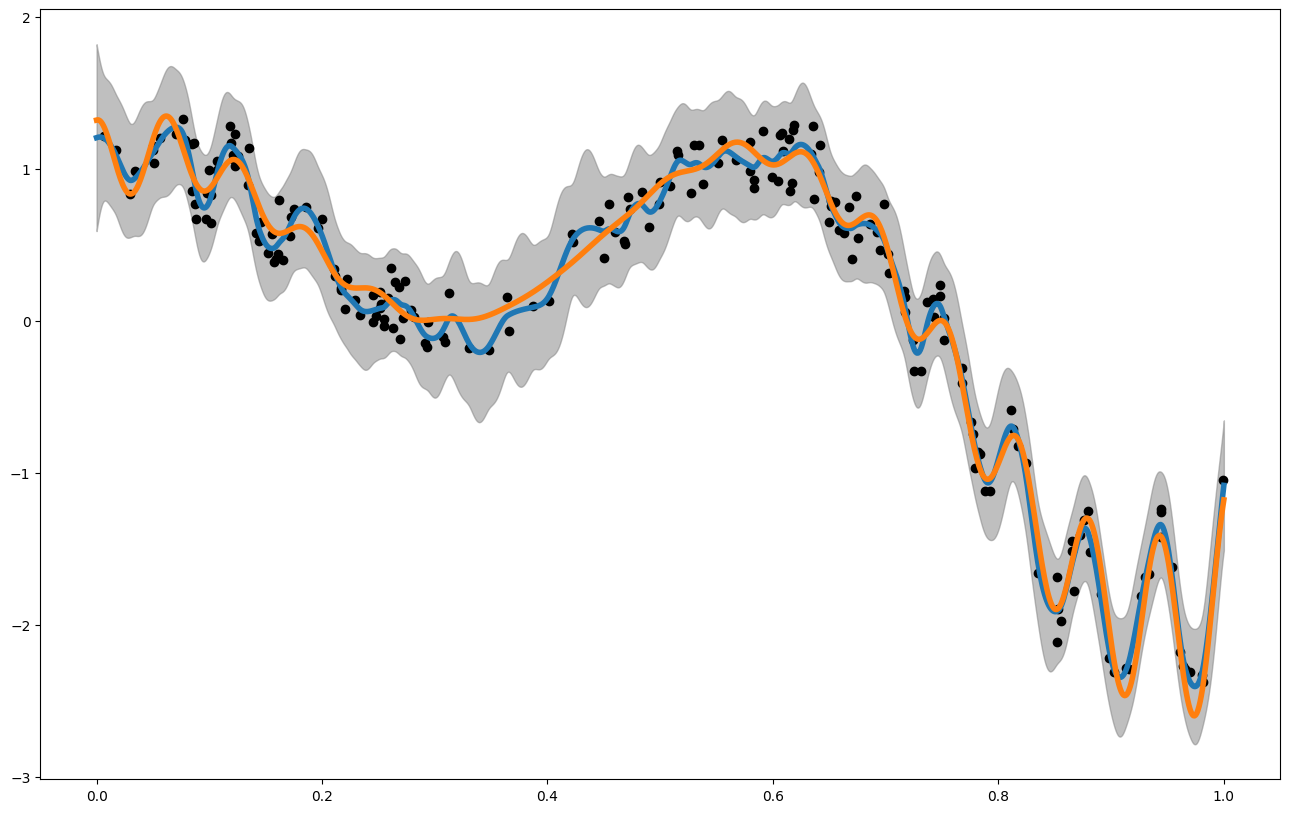

Posterior Mean Gradient


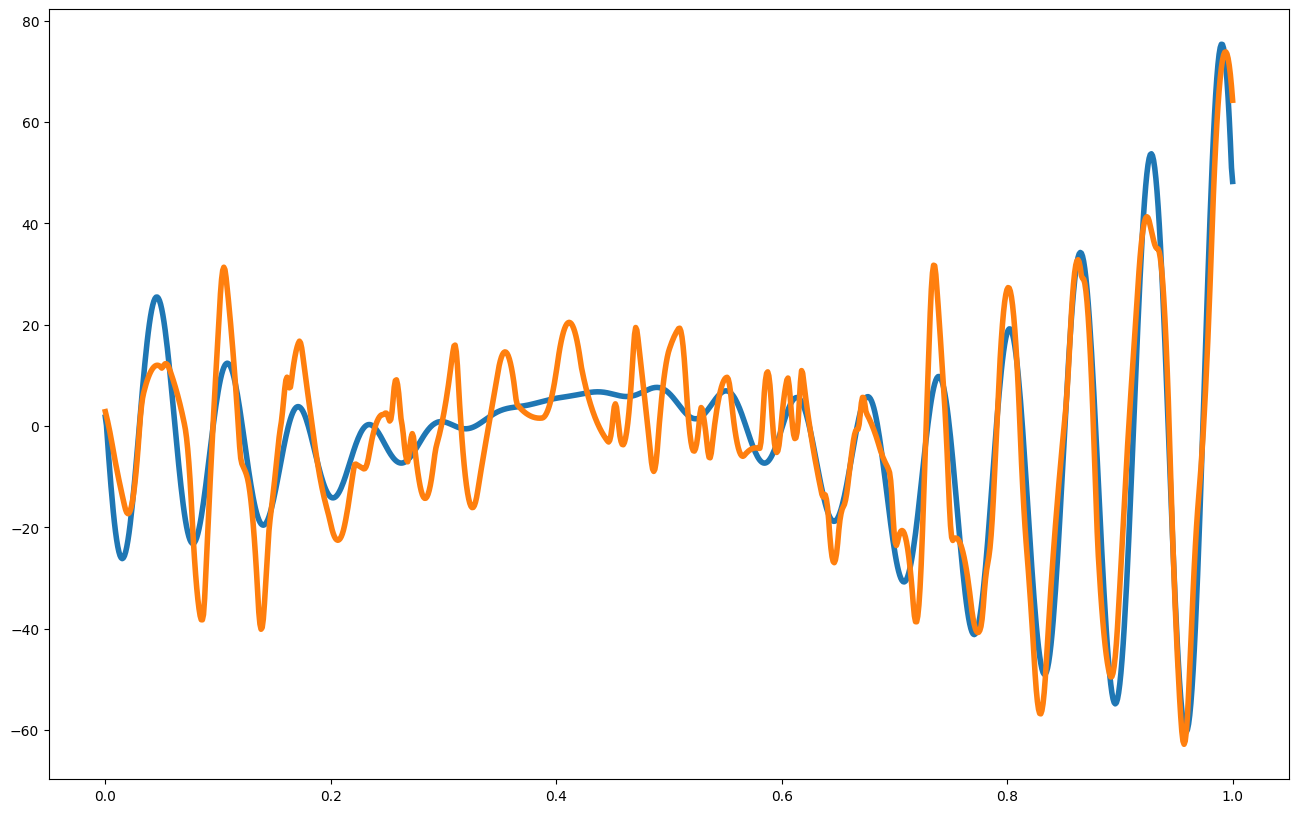

RMSE:              0.0891059646258802
NRMSE:             0.02259333858602979
CRPS (mean, std):  (np.float64(0.05129303033813441), np.float64(0.03658623151637074))
R2:                0.9925423239142481
NLPD:              -0.9488631584209812
MSLL:              -2.4028342965316902
MAPE:              1.1888301154818428
INTERVAL SCORE:    0.49549450863438094
MPIW:              0.49549450863438094
PICP:              1.0
Coverage Curve:


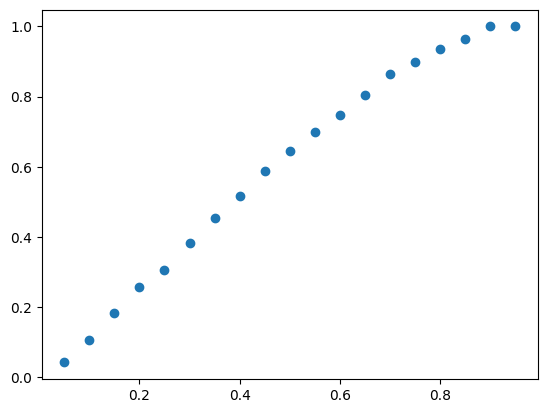

predicted vs. observed


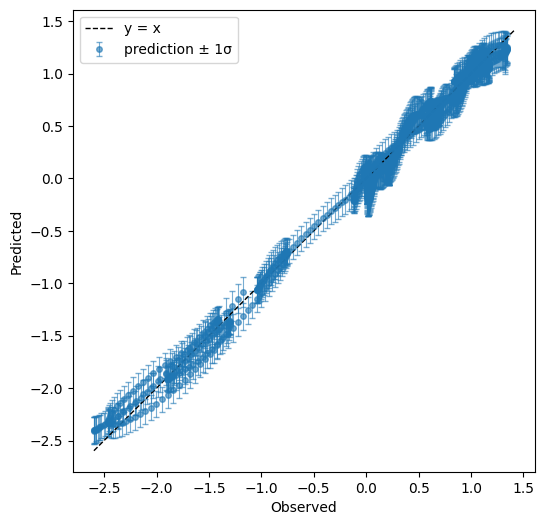

In [14]:
#let's make a prediction
x_pred = np.linspace(0,1,1000)
hps = my_gpo.train(hyperparameter_bounds=hps_bounds, info = False)

# different ways to call 
var1 =  my_gpo.posterior_covariance(x_pred.reshape(-1,1), variance_only=False, add_noise=False)["v(x)"]
var1 =  my_gpo.posterior_covariance(x_pred.reshape(-1,1), variance_only=False, add_noise=True)["v(x)"]

mean1 = my_gpo.posterior_mean(x_pred.reshape(-1,1))["m(x)"]
var1 =  my_gpo.posterior_covariance(x_pred.reshape(-1,1), variance_only=False, add_noise=True)["v(x)"]
mean_grad = my_gpo.posterior_mean_grad(x_pred.reshape(-1,1), direction=0)["dm/dx"]

print("Posterior Mean and Uncertainty")
plt.figure(figsize = (16,10))
plt.plot(x_pred,mean1, label = "posterior mean", linewidth = 4)
plt.plot(x_pred1D,f1(x_pred1D), label = "latent function", linewidth = 4)
plt.fill_between(x_pred, mean1 - 3. * np.sqrt(var1), mean1 + 3. * np.sqrt(var1), alpha = 0.5, color = "grey", label = "var")
plt.scatter(my_gpo.x_data,my_gpo.y_data, color = 'black')
plt.show()

print("Posterior Mean Gradient")
plt.figure(figsize = (16,10))
dx = 1./len(x_pred)
plt.plot(x_pred1D,np.gradient(f1(x_pred1D).flatten(), dx), label = "ground truth gradient", linewidth = 4)
plt.plot(x_pred1D,mean_grad, label = "posterior mean grad", linewidth = 4)
plt.show()



##looking at some validation metrics
print("RMSE:             ",my_gpo.rmse(x_pred1D,f1(x_pred1D).flatten()))
print("NRMSE:            ",my_gpo.nrmse(x_pred1D,f1(x_pred1D).flatten()))
print("CRPS (mean, std): ",my_gpo.crps(x_pred1D,f1(x_pred1D).flatten()))
print("R2:               ",my_gpo.r2(x_pred1D,f1(x_pred1D).flatten()))
print("NLPD:             ",my_gpo.nlpd(x_pred1D,f1(x_pred1D).flatten()))
print("MSLL:             ",my_gpo.msll(x_pred1D,f1(x_pred1D).flatten()))
print("MAPE:             ",my_gpo.mape(x_pred1D,f1(x_pred1D).flatten()))
print("INTERVAL SCORE:   ",my_gpo.interval_score(x_pred1D,f1(x_pred1D).flatten()))
print("MPIW:             ",my_gpo.mpiw(x_pred1D))
print("PICP:             ",my_gpo.picp(x_pred1D,f1(x_pred1D).flatten()))
print("Coverage Curve:")
cov_curve = my_gpo.coverage_curve(x_pred1D,f1(x_pred1D).flatten())
plt.scatter(cov_curve["target_coverage"], cov_curve["measured_coverage"])
plt.show()

print("predicted vs. observed")
my_gpo.plot_observed_vs_predicted(x_pred1D,f1(x_pred1D).flatten())

## Predicted Information Gain

In [15]:
relative_entropy =  my_gpo.gp_relative_information_entropy_set(x_pred.reshape(-1,1))["RIE"]

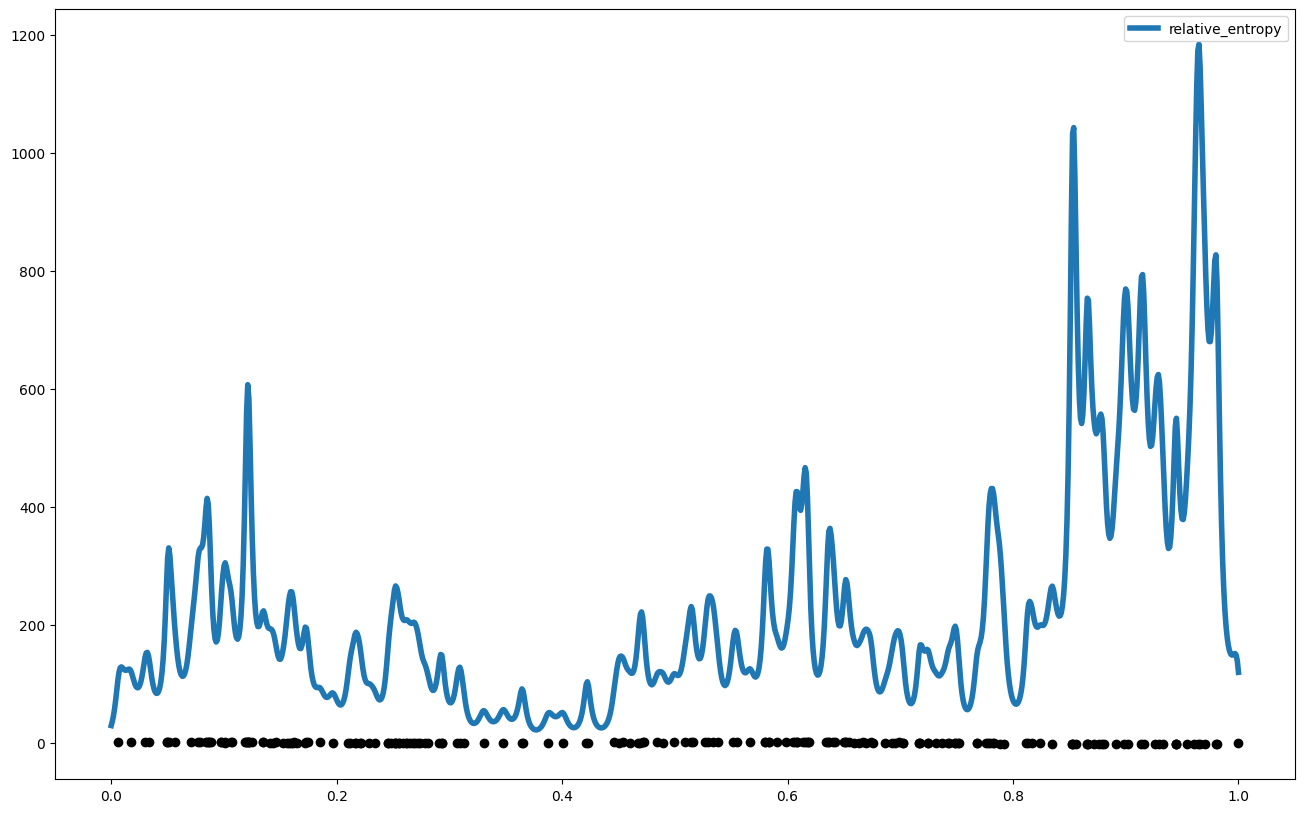

In [16]:
plt.figure(figsize = (16,10))
plt.plot(x_pred,relative_entropy, label = "relative_entropy", linewidth = 4)
plt.scatter(x_data,y_data, color = 'black')
plt.legend()

In [17]:
#We can ask mutual information and total correlation there is given some test data
x_test = np.array([[0.45],[0.45]])
print("MI: ",my_gpo.gp_mutual_information(x_test))
print("TC: ",my_gpo.gp_total_correlation(x_test))
my_gpo.gp_entropy(x_test)
my_gpo.gp_entropy_grad(x_test, 0)
my_gpo.gp_kl_div(x_test, np.ones((len(x_test))), np.identity((len(x_test))))
my_gpo.gp_relative_information_entropy(x_test)
my_gpo.gp_relative_information_entropy_set(x_test)
my_gpo.posterior_covariance(x_test)
my_gpo.posterior_covariance_grad(x_test)
my_gpo.posterior_mean(x_test)
my_gpo.posterior_mean_grad(x_test)
my_gpo.posterior_probability(x_test, np.ones((len(x_test))), np.identity((len(x_test))))

MI:  {'x': array([[0.45],
       [0.45]]), 'x_out': None, 'mutual information': np.float64(5.59173434084164)}
TC:  {'x': array([[0.45],
       [0.45]]), 'x_out': None, 'total correlation': np.float64(15.532808431344733)}


{'x': array([[0.45],
        [0.45]]),
 'x_out': None,
 'mu': array([0.59725158, 0.59725158]),
 'covariance': array([[0.01407243, 0.0035923 ],
        [0.0035923 , 0.01407243]]),
 'probability': np.float64(0.133030183174406)}

## ask()ing for New Measurements
`ask()` maximizes an acquisition function over a search space and returns the next point(s) to
measure; `tell()` adds the measurement to the GP. Here a few acquisition functions -- the notebook
`1dSingleTaskAcqFuncTest` shows all of them, and all optimizers of `ask()`.

variance (the default): [[0.43477773]]
upper confidence bound: [[0.06514244]]
expected improvement:   [[1.40754657e-07]]


/home/marcus/Coding/gpCAM/gpcam/gp_optimizer_base.py:596: UserWarning: I set vectorized=False for total corr. or rel. inf. entropy.
  warnings.warn("I set vectorized=False for total corr. or rel. inf. entropy.")


3 points chosen together (total correlation):
 [[0.99296769]
 [0.40813614]
 [0.33877205]]


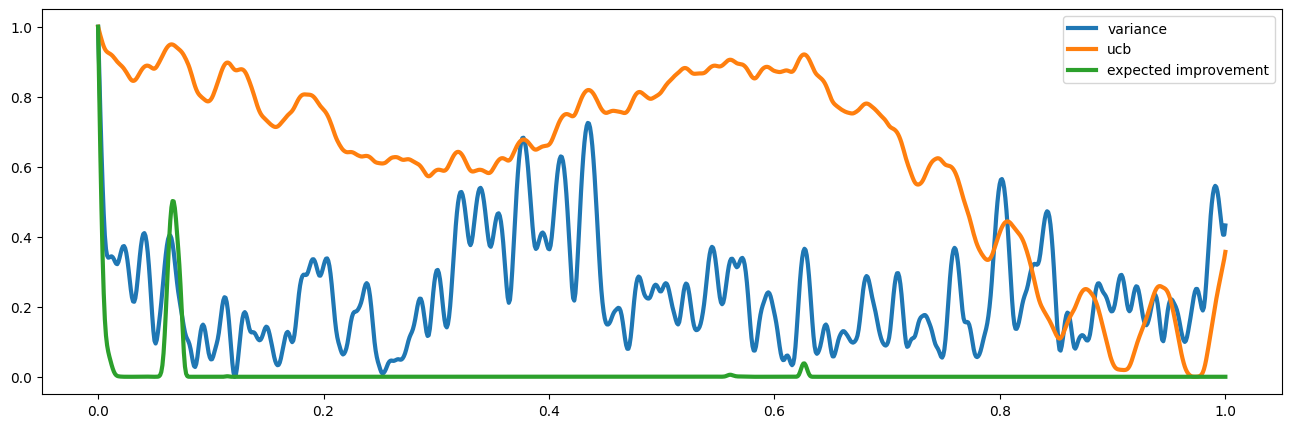

In [18]:
bounds = np.array([[0.,1.]])
print("variance (the default):", my_gpo.ask(bounds)["x"])
print("upper confidence bound:", my_gpo.ask(bounds, acquisition_function="ucb")["x"])
print("expected improvement:  ", my_gpo.ask(bounds, acquisition_function="expected improvement")["x"])
print("3 points chosen together (total correlation):\n", my_gpo.ask(bounds, n=3, acquisition_function="total correlation")["x"])

plt.figure(figsize = (16,5))
for acq_func in ("variance", "ucb", "expected improvement"):
    res = my_gpo.evaluate_acquisition_function(x_pred.reshape(-1,1), acquisition_function=acq_func)
    plt.plot(x_pred, (res - np.min(res)) / (np.max(res) - np.min(res)), label = acq_func, linewidth = 3)
plt.legend()
plt.show()

### An autonomous loop
Ask, measure, tell, and retrain from time to time. `optimize()` does the same for a known function;
see the notebook `GPOptimizer_Optimization`.

In [19]:
for i in range(10):
    x_new = my_gpo.ask(bounds, acquisition_function="variance")["x"]
    y_new = f1(x_new[:,0]) + (np.random.rand(len(x_new))-0.5) * 0.5   #the "measurement"
    my_gpo.tell(x_new, y_new, noise_variances=np.ones(y_new.shape) * 0.01)
    if i % 5 == 4: my_gpo.train(hyperparameter_bounds=hps_bounds)
print("data points:", len(my_gpo.x_data), " hyperparameters:", my_gpo.hyperparameters)

data points: 213  hyperparameters: [0.8733004  0.05590523]


## Low-rank GPs: kernels of known rank
Some kernels have a known, finite rank r: linear, polynomial, or feature-based kernels such as $k(x_1,x_2) = \Phi(x_1)\Phi(x_2)^T$ with r features. For those, `linalg_mode="low_rank_<r>"` factors the covariance matrix K by a rank-r pivoted Cholesky in $O(N r^2)$ and computes the log-likelihood, its gradient and the posterior **exactly** -- through the Woodbury identity and the matrix determinant lemma -- without ever factoring the N x N matrix K + V. The noise has to be one variance per data point.

Here, a kernel of 81 Fourier features (frequencies up to 40 times a learned base frequency) has rank 81, however many data points there are.

In [20]:
def fourier_features(x, frequency, m=40):
    """1 + 2m Fourier features: a constant, and cosines and sines up to m times the base frequency."""
    arg = frequency * np.outer(x[:, 0], np.arange(1, m + 1))
    return np.column_stack([np.ones(len(x)), np.cos(arg), np.sin(arg)])

def fourier_kernel(x1, x2, hps):
    #rank 81 for any number of points
    return hps[0] * fourier_features(x1, hps[1]) @ fourier_features(x2, hps[1]).T

#the same likelihood, computed two ways, on 8000 points
N = 8000
x_big = np.random.rand(N).reshape(-1, 1)
y_big = f1(x_big[:, 0]) + (np.random.rand(N) - 0.5) * 0.5
hps_lr = np.array([0.1, 3.0])
for mode in ("low_rank_81", "Chol"):
    gp = GPOptimizer(x_big, y_big, init_hyperparameters=hps_lr, noise_variances=np.full(N, 0.02),
            kernel_function=fourier_kernel, linalg_mode=mode)
    st = time.time()
    print(f"{mode:12s}: log-likelihood {gp.log_likelihood(hps_lr * 1.1):.6f} in {time.time() - st:.2f} s")

low_rank_81 : log-likelihood 3928.476816 in 0.72 s
Chol        : log-likelihood 3928.476816 in 5.48 s


Training works as for any GP. The gradient still forms each $\partial K / \partial \theta$ as an N x N matrix, so we train on 2000 points.

hyperparameters: [0.02891162 2.57942667] after 52.5 s


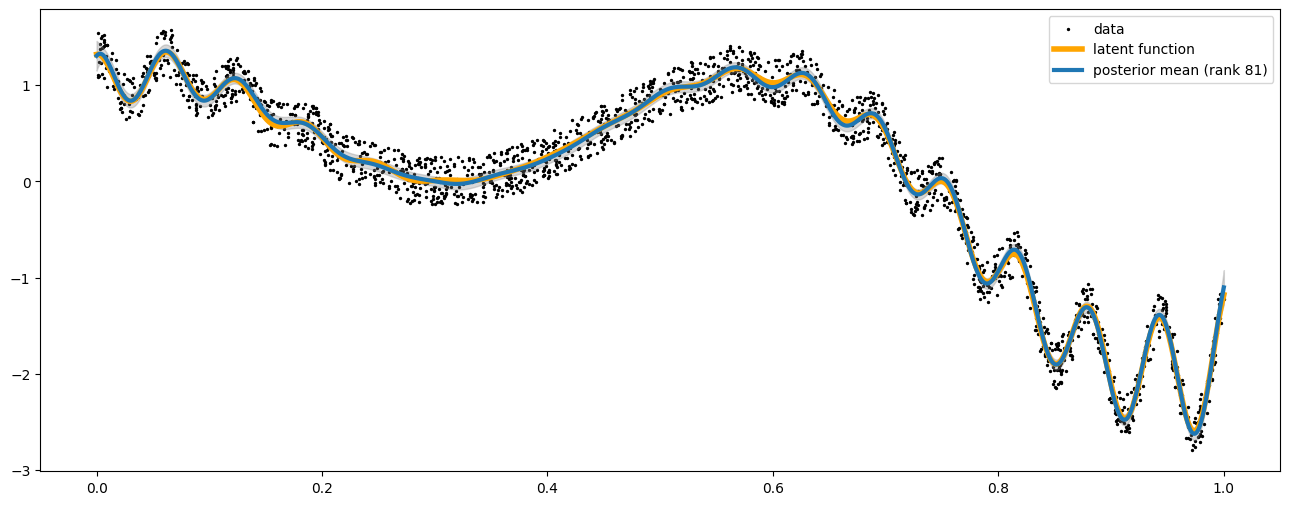

In [21]:
N = 2000
x_lr = np.random.rand(N).reshape(-1, 1)
y_lr = f1(x_lr[:, 0]) + (np.random.rand(N) - 0.5) * 0.5
gp_low_rank = GPOptimizer(x_lr, y_lr, init_hyperparameters=hps_lr, noise_variances=np.full(N, 0.02),
                 kernel_function=fourier_kernel, linalg_mode="low_rank_81")
st = time.time()
gp_low_rank.train(hyperparameter_bounds=np.array([[0.001, 100.], [0.5, 5.]]), n_restarts=2, max_iter=50)
print("hyperparameters:", gp_low_rank.hyperparameters, "after", round(time.time() - st, 1), "s")

mean = gp_low_rank.posterior_mean(x_pred1D)["m(x)"]
sd = np.sqrt(gp_low_rank.posterior_covariance(x_pred1D, variance_only=True)["v(x)"])
plt.figure(figsize = (16,6))
plt.scatter(x_lr[:, 0], y_lr, color = 'black', s = 2, label = "data")
plt.plot(x_pred1D, f1(x_pred1D), color = 'orange', linewidth = 4, label = "latent function")
plt.plot(x_pred1D, mean, linewidth = 3, label = "posterior mean (rank 81)")
plt.fill_between(x_pred1D[:, 0], mean - 3. * sd, mean + 3. * sd, alpha = 0.3, color = "grey")
plt.legend()
plt.show()